# Field development: the selected concept

Notebook 06 screened three concepts. The host's spare gas capacity rules out a
full-rate tieback; one separation stage cannot meet the liquid vapour-pressure limit; two
stages can. This notebook designs the selected three-stage manned platform, sizes its two
export routes, costs the compliant concepts and recommends one.

The field data are repeated here so the notebook runs on its own. They are illustrative.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import azoth
import azoth.eos
import azoth.process
import azoth.pvt
from azoth.core.errors import InvalidInputError, OutOfRangeError

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity
R = 8.314462618
T_SC, P_SC = 288.15, 101325.0
MMSCFD_PER_MOL_S = R * T_SC / P_SC * 86400.0 / 28316.846592
BPD_PER_M3 = 1.0 / 0.158987294928

COMPONENTS = [
    "methane",
    "ethane",
    "propane",
    "i-butane",
    "n-butane",
    "i-pentane",
    "n-pentane",
    "n-hexane",
    "n-heptane",
    "n-octane",
    "co2",
    "nitrogen",
]
Z_FEED = [0.70, 0.08, 0.06, 0.015, 0.03, 0.015, 0.02, 0.02, 0.02, 0.015, 0.02, 0.005]
MIXTURE, IDEAL = azoth.eos.components.mixture_of(COMPONENTS)
MOLAR_MASS = [component.molar_mass.to("kg/mol").magnitude for component in MIXTURE.components]

P_RES, T_RES = 320.0, 383.15
P_WH, T_WH = 95.0, 363.15
P_FIRST = 60.0
WELLSTREAM = 2000.0
HOST_GAS, HOST_LIQ, HOST_P = 50.0, 30_000.0, 45.0
TIEBACK_KM, TRUNK_KM, ONSHORE_KM = 30.0, 15.0, 150.0
P_EXPORT, P_LIQ = 90.0, 20.0
T_VC = 310.93
LIQ_SPEC = 5.0
T_COOL = 313.15
USD = 1.0e6


def norm(z):
    total = float(sum(z))
    return [float(value) / total for value in z]


def mix_streams(n1, z1, n2, z2):
    if n1 <= 0.0:
        return float(n2), list(z2)
    if n2 <= 0.0:
        return float(n1), list(z1)
    total = n1 + n2
    return total, [(n1 * a + n2 * b) / total for a, b in zip(z1, z2, strict=True)]


def boost_gas(n_mol_s, z, p_in, p_out, eta=0.78, t_cool=T_COOL, ratio_max=2.5):
    stages = max(1, math.ceil(math.log(p_out / p_in) / math.log(ratio_max)))
    ratio = (p_out / p_in) ** (1.0 / stages)
    power = duty = 0.0
    n, z = float(n_mol_s), norm(z)
    p, t = p_in, t_cool
    for _ in range(stages):
        compressed = azoth.process.compressor(
            COMPONENTS,
            q(n, "mol/s"),
            z,
            q(p, "bar"),
            q(t, "K"),
            eta,
            outlet_pressure=q(p * ratio, "bar"),
        )
        power += compressed.power.to("kW").magnitude
        cooled = azoth.process.cooler(
            COMPONENTS,
            compressed.outlet_n,
            list(compressed.outlet_z),
            compressed.outlet_p,
            compressed.outlet_t,
            outlet_temperature=q(t_cool, "K"),
        )
        duty += abs(cooled.outlet_duty.to("kW").magnitude)
        n = cooled.outlet_n.to("mol/s").magnitude
        z = norm(list(cooled.outlet_z))
        p = cooled.outlet_p.to("bar").magnitude
    return {"n": n, "z": z, "power_kw": power, "duty_kw": duty, "stages": stages}


def stock_tank(n_mol_s, z):
    z = norm(z)
    flash = azoth.eos.pt_flash(MIXTURE, q(T_SC, "K"), q(P_SC, "bar"), z)
    if flash.phase.value == "all_liquid":
        beta, x = 0.0, z
    elif flash.phase.value in {"all_vapour", "trivial"}:
        beta, x = 1.0, z
    else:
        beta = max(0.0, min(1.0, flash.vapour_fraction or 0.0))
        x = list(flash.x)
    n_liq, n_gas = n_mol_s * (1.0 - beta), n_mol_s * beta
    if n_liq <= 0.0:
        return {"bpd": 0.0, "gas_n": n_gas, "gas_z": z}
    m_liq = sum(a * b for a, b in zip(x, MOLAR_MASS, strict=True))
    v_liq = azoth.eos.pr_molar_volume(flash.z_liquid, q(T_SC, "K"), q(P_SC, "bar")).v
    rho = azoth.eos.pr_mass_density(q(m_liq, "kg/mol"), v_liq).rho.to("kg/m**3").magnitude
    return {"bpd": n_liq * m_liq / rho * 86400.0 * BPD_PER_M3, "gas_n": n_gas, "gas_z": z}


def run_train(later, total=WELLSTREAM, design=False):
    kwargs = {
        "mechanical_design": design,
        "design_gas_load_factor": q(0.11, "m/s") if design else None,
    }
    wellhead = azoth.eos.pt_flash(MIXTURE, q(T_WH, "K"), q(P_WH, "bar"), Z_FEED)
    beta = wellhead.vapour_fraction
    h_v = (
        azoth.eos.molar_enthalpy_entropy(
            MIXTURE, IDEAL, q(T_WH, "K"), q(P_WH, "bar"), list(wellhead.y), wellhead.z_vapour
        )
        .h.to("J/mol")
        .magnitude
    )
    h_l = (
        azoth.eos.molar_enthalpy_entropy(
            MIXTURE, IDEAL, q(T_WH, "K"), q(P_WH, "bar"), list(wellhead.x), wellhead.z_liquid
        )
        .h.to("J/mol")
        .magnitude
    )
    choke = azoth.eos.ph_flash(
        MIXTURE, IDEAL, q(P_FIRST, "bar"), q(beta * h_v + (1.0 - beta) * h_l, "J/mol"), Z_FEED
    )
    t_first = choke.T
    vessel = azoth.process.separator(
        COMPONENTS,
        q(total, "mol/s"),
        Z_FEED,
        q(P_WH, "bar"),
        t_first,
        q(P_WH - P_FIRST, "bar"),
        0.0,
        **kwargs,
    )
    gases = [(vessel.vapour_n.to("mol/s").magnitude, list(vessel.vapour_z), P_FIRST)]
    stages = [
        {
            "stage": 1,
            "p": P_FIRST,
            "t": t_first.to("K").magnitude,
            "gas": vessel.vapour_n.to("mol/s").magnitude,
            "liquid": vessel.liquid_n.to("mol/s").magnitude,
            "separator": vessel,
        }
    ]
    n, z, p, t = vessel.liquid_n, list(vessel.liquid_z), vessel.liquid_p, vessel.liquid_t
    for index, target in enumerate(later, start=2):
        valve = azoth.process.throttling_valve(
            COMPONENTS, n, z, p, t, outlet_pressure=q(target, "bar")
        )
        vessel = azoth.process.separator(
            COMPONENTS,
            valve.outlet_n,
            list(valve.outlet_z),
            valve.outlet_p,
            valve.outlet_t,
            q(0.0, "bar"),
            0.0,
            **kwargs,
        )
        gases.append((vessel.vapour_n.to("mol/s").magnitude, list(vessel.vapour_z), target))
        stages.append(
            {
                "stage": index,
                "p": target,
                "t": vessel.vapour_t.to("K").magnitude,
                "gas": vessel.vapour_n.to("mol/s").magnitude,
                "liquid": vessel.liquid_n.to("mol/s").magnitude,
                "separator": vessel,
            }
        )
        n, z, p, t = vessel.liquid_n, list(vessel.liquid_z), vessel.liquid_p, vessel.liquid_t

    power = duty = 0.0
    gas_n, gas_z = 0.0, None
    compression = []
    for gn, gz, gp in gases:
        boost = boost_gas(gn, gz, gp, P_EXPORT)
        power += boost["power_kw"]
        duty += boost["duty_kw"]
        gas_n, gas_z = mix_streams(gas_n, gas_z, boost["n"], boost["z"])
        compression.append(boost)
    n_liq, z_liq = n.to("mol/s").magnitude, list(z)
    bubble = (
        azoth.eos.bubble_pressure(MIXTURE, q(T_VC, "K"), norm(z_liq)).pressure.to("bar").magnitude
    )
    tank = stock_tank(n_liq, z_liq)
    pump_kw = pump_head = 0.0
    if p.to("bar").magnitude < P_LIQ + 5.0:
        pump = azoth.process.pump(
            COMPONENTS,
            q(n_liq, "mol/s"),
            norm(z_liq),
            p,
            t,
            0.75,
            outlet_pressure=q(P_LIQ + 5.0, "bar"),
        )
        pump_kw = pump.power.to("kW").magnitude
        pump_head = pump.head.to("m").magnitude if pump.head is not None else 0.0
    return {
        "stages": stages,
        "n_gas": gas_n,
        "z_gas": gas_z,
        "sales_n": gas_n + tank["gas_n"],
        "bpd": tank["bpd"],
        "bubble": bubble,
        "power_kw": power,
        "duty_kw": duty,
        "n_liq": n_liq,
        "z_liq": z_liq,
        "pump_kw": pump_kw,
        "pump_head": pump_head,
        "compression": compression,
    }


detail = run_train([10, 2], design=True)
one_stage = run_train([], design=True)
print(
    f"selected: {detail['sales_n'] * MMSCFD_PER_MOL_S:.1f} MMscfd, "
    f"{detail['bpd']:.0f} bbl/d, bubble {detail['bubble']:.2f} bara, "
    f"{detail['power_kw'] / 1000.0:.2f} MW"
)

selected: 137.2 MMscfd, 6107 bbl/d, bubble 1.50 bara, 2.40 MW


## 1. The selected train

The three-stage train at 60/10/2 bara is sized on the API 12J gas load factor. The
separators hold the choke outlet temperature, the lower stages take the isenthalpic let-down,
and the gas from each stage is compressed to the 90 bara export pressure.

In [2]:
rows = []
for stage in detail["stages"]:
    vessel = stage["separator"]
    rows.append(
        {
            "stage": stage["stage"],
            "pressure (bara)": stage["p"],
            "temperature (K)": round(stage["t"], 1),
            "gas (mol/s)": round(stage["gas"], 1),
            "liquid (mol/s)": round(stage["liquid"], 1),
            "D (m)": round(vessel.design_inner_diameter.to("m").magnitude, 2),
            "L (m)": round(vessel.design_tantan_length.to("m").magnitude, 2),
            "volume (m3)": round(vessel.vessel_volume.to("m**3").magnitude, 1),
            "weight (t)": round(vessel.total_weight.to("kg").magnitude / 1000.0, 1),
        }
    )
separators = pd.DataFrame(rows)
compressors = pd.DataFrame(
    [
        {
            "service": f"stage {index + 1} gas",
            "stages": boost["stages"],
            "power (kW)": round(boost["power_kw"]),
            "cooling (kW)": round(boost["duty_kw"]),
        }
        for index, boost in enumerate(detail["compression"])
    ]
)
print(
    f"sales gas {detail['sales_n'] * MMSCFD_PER_MOL_S:.1f} MMscfd | "
    f"stock tank {detail['bpd']:.0f} bbl/d | pump {detail['pump_kw']:.0f} kW"
)
display(separators)
display(compressors)

sales gas 137.2 MMscfd | stock tank 6107 bbl/d | pump 42 kW


,stage,pressure (bara),temperature (K),gas (mol/s),liquid (mol/s),D (m),L (m),volume (m3),weight (t)
0,1,60.0,353.9,1822.8,177.2,1.96,7.26,21.9,78.9
1,2,10.0,338.7,59.3,117.9,1.61,8.03,16.3,58.7
2,3,2.0,324.7,19.5,98.4,1.53,7.64,14.0,50.6


,service,stages,power (kW),cooling (kW)
0,stage 1 gas,1,1942,3478
1,stage 2 gas,3,337,687
2,stage 3 gas,5,121,420


## 2. The export routes

The platform can tie into the trunk 15 km away, or send gas and liquid 150 km to the
onshore plant. The gas is saturated at the 90 bara export pressure and 40 °C, so the wet-gas
line is the isothermal Beggs-Brills march rather than a dry-gas equation; the stabilised
liquid is single-phase and takes the same march's liquid branch.

The trunk receives gas at 60 bara and liquid at 20 bara; the onshore plant receives gas at
40 bara and liquid at 15 bara.

In [3]:
gas_export = azoth.eos.pt_flash(MIXTURE, q(T_COOL, "K"), q(P_EXPORT, "bar"), norm(detail["z_gas"]))
if gas_export.phase.value == "two_phase":
    gas_line_n = detail["n_gas"] * gas_export.vapour_fraction
    gas_line_z = norm(list(gas_export.y))
else:
    gas_line_n, gas_line_z = detail["n_gas"], norm(detail["z_gas"])

rows = []
for label, distance, reception in (("trunk", TRUNK_KM, 60.0), ("onshore", ONSHORE_KM, 40.0)):
    for inches, diameter in ((12, 0.3048), (14, 0.3556), (16, 0.4064), (18, 0.4572)):
        try:
            line = azoth.eos.pipe_beggs_and_brills(
                COMPONENTS,
                gas_line_n,
                gas_line_z,
                q(P_EXPORT, "bar"),
                q(T_COOL, "K"),
                q(distance * 1000.0, "m"),
                q(diameter, "m"),
                q(0.0, "m"),
                30,
                q(4.6e-5, "m"),
            )
            arrival = line.outlet_pressure.to("bar").magnitude
            rows.append(
                {
                    "route": label,
                    "line (in)": inches,
                    "arrival (bara)": round(arrival, 1),
                    "reception (bara)": reception,
                    "reception": "met" if arrival >= reception else "not met",
                }
            )
        except (InvalidInputError, OutOfRangeError):
            rows.append(
                {
                    "route": label,
                    "line (in)": inches,
                    "arrival (bara)": np.nan,
                    "reception (bara)": reception,
                    "reception": "line does not deliver",
                }
            )
for label, distance, reception, discharge in (
    ("trunk", TRUNK_KM, 20.0, 25.0),
    ("onshore", ONSHORE_KM, 15.0, 30.0),
):
    for inches, diameter in ((6, 0.1524), (8, 0.2032), (10, 0.254)):
        try:
            line = azoth.eos.pipe_beggs_and_brills(
                COMPONENTS,
                detail["n_liq"],
                norm(detail["z_liq"]),
                q(discharge, "bar"),
                q(T_COOL, "K"),
                q(distance * 1000.0, "m"),
                q(diameter, "m"),
                q(0.0, "m"),
                30,
                q(4.6e-5, "m"),
            )
            arrival = line.outlet_pressure.to("bar").magnitude
            rows.append(
                {
                    "route": label + " liquid",
                    "line (in)": inches,
                    "arrival (bara)": round(arrival, 1),
                    "reception (bara)": reception,
                    "reception": "met" if arrival >= reception else "not met",
                }
            )
        except (InvalidInputError, OutOfRangeError):
            rows.append(
                {
                    "route": label + " liquid",
                    "line (in)": inches,
                    "arrival (bara)": np.nan,
                    "reception (bara)": reception,
                    "reception": "line does not deliver",
                }
            )
lines = pd.DataFrame(rows)
print(
    f"gas line {gas_line_n * MMSCFD_PER_MOL_S:.1f} MMscfd | "
    f"liquid {detail['bpd']:.0f} bbl/d at {detail['n_liq']:.0f} mol/s"
)
lines

gas line 122.4 MMscfd | liquid 6107 bbl/d at 98 mol/s


,route,line (in),arrival (bara),reception (bara),reception
0,trunk,12,76.5,60.0,met
1,trunk,14,84.9,60.0,met
2,trunk,16,87.9,60.0,met
3,trunk,18,88.6,60.0,met
4,onshore,12,NaN,40.0,line does not deliver
5,onshore,14,NaN,40.0,line does not deliver
6,onshore,16,63.5,40.0,met
7,onshore,18,75.1,40.0,met
8,trunk liquid,6,22.0,20.0,met
9,trunk liquid,8,24.3,20.0,met


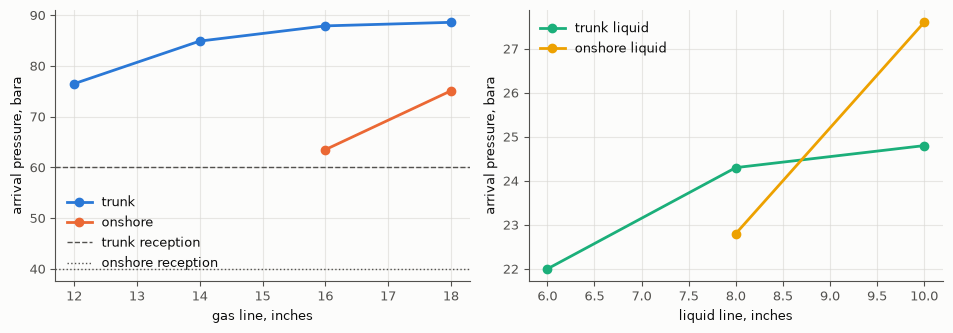

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.4))
for label, colour in (("trunk", PALETTE[0]), ("onshore", PALETTE[1])):
    group = lines[(lines["route"] == label) & lines["arrival (bara)"].notna()]
    left.plot(group["line (in)"], group["arrival (bara)"], "o-", color=colour, label=label)
left.axhline(60.0, color=MUTED, linestyle="--", linewidth=1.0, label="trunk reception")
left.axhline(40.0, color=MUTED, linestyle=":", linewidth=1.0, label="onshore reception")
left.set_xlabel("gas line, inches")
left.set_ylabel("arrival pressure, bara")
left.legend(frameon=False)
for label, colour in (("trunk liquid", PALETTE[2]), ("onshore liquid", PALETTE[3])):
    group = lines[(lines["route"] == label) & lines["arrival (bara)"].notna()]
    right.plot(group["line (in)"], group["arrival (bara)"], "o-", color=colour, label=label)
right.set_xlabel("liquid line, inches")
right.set_ylabel("arrival pressure, bara")
right.legend(frameon=False)
plt.tight_layout()
plt.show()
plt.close(fig)

## 3. What the concepts cost

The process equipment is priced by the library's NeqSim/Turton stack and rolled up by
`topsides_facility_cost`. Pipelines, the jacket and installation, the well and the host tie-in
are stated study rates: the library's pipe cost is a plant-piping correlation, not an
offshore installation rate. The rates are listed with the table so the sensitivity can move
them.

In [5]:
def process_cost_rows(detail):
    rows = []
    for stage in detail["stages"]:
        vessel = stage["separator"]
        rows.append(
            {
                "equipment": "separator",
                "name": f"Stage {stage['stage']} separator",
                "inner_diameter": vessel.design_inner_diameter,
                "tangent_length": vessel.design_tantan_length,
                "weight_total": vessel.total_weight,
                "mechanical_design_present": True,
                "max_design_pressure": q(stage["p"] * 1.1 + 1.0, "bar"),
            }
        )
    for index, boost in enumerate(detail["compression"]):
        rows.append(
            {
                "equipment": "compressor",
                "name": f"Export compression {index + 1}",
                "power": q(boost["power_kw"], "kW"),
                "compressor_type": "centrifugal",
                "driver_type": "gas-turbine",
                "include_driver": True,
                "weight_total": q(boost["power_kw"] * 12.0, "kg"),
                "mechanical_design_present": True,
                "max_design_pressure": q(100.0, "bar"),
            }
        )
        rows.append(
            {
                "equipment": "heat_exchanger",
                "name": f"Aftercooler {index + 1}",
                "duty": q(boost["duty_kw"], "kW"),
                "weight_total": q(max(boost["duty_kw"] * 0.8, 500.0), "kg"),
                "mechanical_design_present": True,
                "max_design_pressure": q(100.0, "bar"),
                "exchanger_type": "air-cooler",
            }
        )
    if detail["pump_kw"] > 0.0:
        rows.append(
            {
                "equipment": "pump",
                "name": "Condensate export pump",
                "power": q(detail["pump_kw"], "kW"),
                "pump_type": "centrifugal",
                "include_motor": True,
                "weight_total": q(1500.0, "kg"),
                "mechanical_design_present": True,
                "max_design_pressure": q(40.0, "bar"),
            }
        )
    return rows


def topsides_cost(detail):
    specs = process_cost_rows(detail)
    cost = azoth.process.equipment_cost_estimate(specs)
    mapping = {
        "vessel": "Vessels",
        "compressor": "Compressors",
        "exchanger": "Heat Exchangers",
        "pump": "Pumps",
    }
    topsides_rows = [
        {
            "name": item.name,
            "equipment_type": mapping[item.equipment_type],
            "total_module_cost": item.total_module_cost,
            "weight": spec["weight_total"],
        }
        for item, spec in zip(cost.equipment, specs, strict=True)
    ]
    facility = azoth.process.topsides_facility_cost(
        topsides_rows, facility_type="fixed_platform", project_context="greenfield"
    )
    process_class = {
        "vessel": "Separator",
        "compressor": "Compressor",
        "exchanger": "Cooler",
        "pump": "Pump",
    }
    process = azoth.process.process_cost_estimate(
        [
            {
                "name": item.name,
                "equipment_class": process_class[item.equipment_type],
                "purchased_equipment_cost": item.purchased_equipment_cost,
                "bare_module_cost": item.bare_module_cost,
                "total_module_cost": item.total_module_cost,
                "grass_roots_cost": item.grass_roots_cost,
                "total_cost": item.total_module_cost,
                "installation_man_hours": item.installation_man_hours,
                "weight": spec["weight_total"],
            }
            for item, spec in zip(cost.equipment, specs, strict=True)
        ],
        operating_hours=q(8000.0, "h"),
        electricity_cost_per_kwh=0.10,
    )
    electricity = sum(line.cost for line in process.operating_costs if line.name == "Electricity")
    return facility.project_cost_summary[0].cost, electricity, cost


manned_topsides, manned_electricity, manned_equipment = topsides_cost(detail)
nui_topsides, nui_electricity, nui_equipment = topsides_cost(one_stage)

WELL_COST, TREE_COST, HOST_TIE_IN = 75.0 * USD, 30.0 * USD, 20.0 * USD
JACKET_NUI, JACKET_MANNED = 180.0 * USD, 320.0 * USD
LINE_RATE = {
    6: 1.5 * USD,
    8: 2.0 * USD,
    10: 3.0 * USD,
    12: 4.0 * USD,
    14: 5.0 * USD,
    16: 5.5 * USD,
    18: 6.0 * USD,
}

capex = pd.DataFrame(
    [
        {
            "concept": "tieback curtailed",
            "well": WELL_COST,
            "platform": 0.0,
            "process": TREE_COST,
            "pipelines": 30.0 * LINE_RATE[10] + HOST_TIE_IN,
            "total": WELL_COST + TREE_COST + 30.0 * LINE_RATE[10] + HOST_TIE_IN,
        },
        {
            "concept": "NUI, one separator",
            "well": WELL_COST,
            "platform": JACKET_NUI,
            "process": nui_topsides,
            "pipelines": 15.0 * LINE_RATE[12] + 15.0 * LINE_RATE[6],
            "total": WELL_COST
            + JACKET_NUI
            + nui_topsides
            + 15.0 * LINE_RATE[12]
            + 15.0 * LINE_RATE[6],
        },
        {
            "concept": "manned, trunk",
            "well": WELL_COST,
            "platform": JACKET_MANNED,
            "process": manned_topsides,
            "pipelines": 15.0 * LINE_RATE[12] + 15.0 * LINE_RATE[6],
            "total": WELL_COST
            + JACKET_MANNED
            + manned_topsides
            + 15.0 * LINE_RATE[12]
            + 15.0 * LINE_RATE[6],
        },
        {
            "concept": "manned, onshore",
            "well": WELL_COST,
            "platform": JACKET_MANNED,
            "process": manned_topsides,
            "pipelines": 150.0 * LINE_RATE[16] + 150.0 * LINE_RATE[10],
            "total": WELL_COST
            + JACKET_MANNED
            + manned_topsides
            + 150.0 * LINE_RATE[16]
            + 150.0 * LINE_RATE[10],
        },
    ]
)
for column in ("well", "platform", "process", "pipelines", "total"):
    capex[column] = (capex[column] / USD).round(0)
print("CAPEX, USD million; pipeline rates are study assumptions")
display(capex)
print("line rates (USD million per km):", {key: value / USD for key, value in LINE_RATE.items()})

CAPEX, USD million; pipeline rates are study assumptions


,concept,well,platform,process,pipelines,total
0,tieback curtailed,75.0,0.0,30.0,110.0,215.0
1,"NUI, one separator",75.0,180.0,58.0,82.0,395.0
2,"manned, trunk",75.0,320.0,85.0,82.0,562.0
3,"manned, onshore",75.0,320.0,85.0,1275.0,1755.0


line rates (USD million per km): {6: 1.5, 8: 2.0, 10: 3.0, 12: 4.0, 14: 5.0, 16: 5.5, 18: 6.0}


## 4. Production, operating cost and value

The field produces at 137 MMscfd and 6,100 bbl/d for five years and then declines at
10 %/year on an Arps hyperbolic `b = 0.8` forecast. The tieback is capped at the host's
50 MMscfd, with the liquids scaled by the same gas ratio; once the field falls below the cap
the tieback ships the whole rate.

Gas is sold at 4 USD/MMBtu with a 1.05 MMBtu/Mscf heating value, liquids at 70 USD/bbl. The
discount rate is 10 % and the project life 20 years. The platform's fixed operating cost is
30 USD million/year, the NUI's 12, and the tieback carries a 5 USD million/year host fee plus
0.75 USD/MMBtu and 2 USD/bbl tariffs.

In [6]:
PLATEAU_YEARS = 5.0
DECLINE = 0.10
GAS_PRICE, LIQUID_PRICE = 4.0, 70.0
DISCOUNT = 0.10
YEARS = 20
forecast = azoth.pvt.decline_curve(
    "forecast",
    qi=WELLSTREAM,
    di=DECLINE / 365.25,
    b=0.8,
    t_start=0.0,
    t_end=(YEARS - PLATEAU_YEARS) * 365.25,
    t_step=365.25,
)
rates = np.concatenate([np.full(int(PLATEAU_YEARS), WELLSTREAM), np.array(forecast.rate[1:])])[
    :YEARS
]
years = np.arange(1, YEARS + 1)
gas = rates * (detail["sales_n"] / WELLSTREAM) * MMSCFD_PER_MOL_S
liquid = rates * (detail["bpd"] / WELLSTREAM)
print(
    f"year 1: {gas[0]:.1f} MMscfd, {liquid[0]:.0f} bbl/d; "
    f"year 10: {gas[9]:.1f} MMscfd, {liquid[9]:.0f} bbl/d"
)

concepts = {
    "tieback curtailed": {
        "capex": capex.loc[0, "total"] * USD,
        "fixed": 5.0 * USD,
        "electricity": 0.0,
        "tariff_gas": 0.75,
        "tariff_liquid": 2.0,
        "tieback": True,
    },
    "NUI (non-compliant)": {
        "capex": capex.loc[1, "total"] * USD,
        "fixed": 12.0 * USD,
        "electricity": nui_electricity,
        "tariff_gas": 0.0,
        "tariff_liquid": 0.0,
        "tieback": False,
    },
    "manned, trunk": {
        "capex": capex.loc[2, "total"] * USD,
        "fixed": 30.0 * USD,
        "electricity": manned_electricity,
        "tariff_gas": 0.0,
        "tariff_liquid": 0.0,
        "tieback": False,
    },
    "manned, onshore": {
        "capex": capex.loc[3, "total"] * USD,
        "fixed": 30.0 * USD,
        "electricity": manned_electricity,
        "tariff_gas": 0.0,
        "tariff_liquid": 0.0,
        "tieback": False,
    },
}


def cash_flow(
    concept, gas_price=GAS_PRICE, liquid_price=LIQUID_PRICE, discount=DISCOUNT, capex_multiplier=1.0
):
    gas_sold = gas.copy()
    liquid_sold = liquid.copy()
    if concept["tieback"]:
        gas_sold = np.minimum(gas, HOST_GAS)
        liquid_sold = liquid * np.divide(gas_sold, gas, out=np.zeros_like(gas), where=gas > 0)
    revenue = gas_sold * 365.0 * 1.05e3 * gas_price + liquid_sold * 365.0 * liquid_price
    electricity = concept["electricity"] * rates / WELLSTREAM
    tariff = gas_sold * 365.0 * 1.05e3 * concept["tariff_gas"]
    tariff += liquid_sold * 365.0 * concept["tariff_liquid"]
    cash = revenue - concept["fixed"] - electricity - tariff
    npv = -concept["capex"] * capex_multiplier + sum(
        value / (1.0 + discount) ** year for year, value in zip(years, cash, strict=True)
    )
    return npv, cash


summary = []
for name, concept in concepts.items():
    npv, cash = cash_flow(concept)
    cumulative = np.cumsum(cash) - concept["capex"]
    payback = next(
        (year for year, value in zip(years, cumulative, strict=True) if value >= 0.0), np.nan
    )
    summary.append(
        {
            "concept": name,
            "capex (MUSD)": round(concept["capex"] / USD),
            "NPV (MUSD)": round(npv / USD),
            "payback (years)": payback,
            "year-1 cash (MUSD)": round(cash[0] / USD),
        }
    )
summary = pd.DataFrame(summary)
summary

year 1: 137.2 MMscfd, 6107 bbl/d; year 10: 90.1 MMscfd, 4010 bbl/d


,concept,capex (MUSD),NPV (MUSD),payback (years),year-1 cash (MUSD)
0,tieback curtailed,215,743,2,113
1,NUI (non-compliant),395,2001,2,354
2,"manned, trunk",562,1681,2,336
3,"manned, onshore",1755,488,6,336


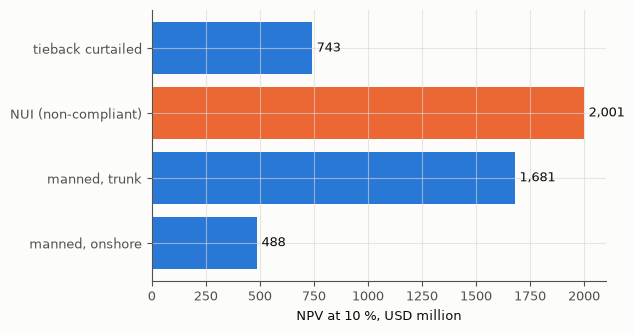

In [7]:
fig, ax = plt.subplots()
ordered = summary.iloc[::-1]
colours = [PALETTE[1] if name.startswith("NUI") else PALETTE[0] for name in ordered["concept"]]
ax.barh(ordered["concept"], ordered["NPV (MUSD)"], color=colours)
ax.set_xlabel("NPV at 10 %, USD million")
for bar, value in zip(ax.patches, ordered["NPV (MUSD)"], strict=True):
    ax.text(
        value + 20.0, bar.get_y() + bar.get_height() / 2.0, f"{value:,.0f}", va="center", color=INK
    )
plt.tight_layout()
plt.show()
plt.close(fig)

## 5. What moves the answer

The manned platform is the best compliant concept. The sensitivity asks how far the key
assumptions have to move before the tieback overtakes it: the gas price, the liquid price,
the platform capex and the discount rate. A second table
finds the platform-capex multiplier at which the two are equal.

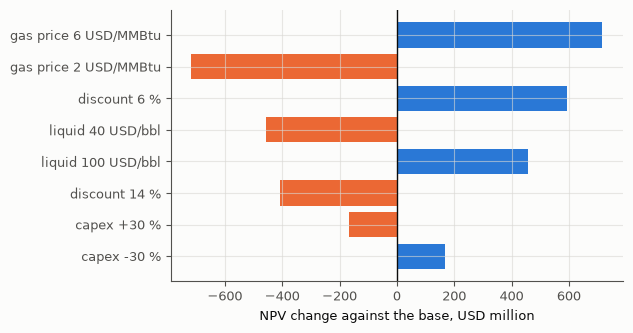

manned platform NPV at base: 1,681 MUSD; tieback: 743 MUSD
the platform capex would need to rise by a factor of 2.67 before the tieback overtakes it


In [8]:
base, _ = cash_flow(concepts["manned, trunk"])
variants = {
    "gas price 2 USD/MMBtu": cash_flow(concepts["manned, trunk"], gas_price=2.0)[0],
    "gas price 6 USD/MMBtu": cash_flow(concepts["manned, trunk"], gas_price=6.0)[0],
    "liquid 40 USD/bbl": cash_flow(concepts["manned, trunk"], liquid_price=40.0)[0],
    "liquid 100 USD/bbl": cash_flow(concepts["manned, trunk"], liquid_price=100.0)[0],
    "capex -30 %": cash_flow(concepts["manned, trunk"], capex_multiplier=0.7)[0],
    "capex +30 %": cash_flow(concepts["manned, trunk"], capex_multiplier=1.3)[0],
    "discount 6 %": cash_flow(concepts["manned, trunk"], discount=0.06)[0],
    "discount 14 %": cash_flow(concepts["manned, trunk"], discount=0.14)[0],
}
swing = {name: (value - base) / USD for name, value in variants.items()}
swing = dict(sorted(swing.items(), key=lambda item: abs(item[1])))

fig, ax = plt.subplots()
ax.barh(
    list(swing),
    list(swing.values()),
    color=[PALETTE[0] if value >= 0 else PALETTE[1] for value in swing.values()],
)
ax.axvline(0.0, color=INK, linewidth=1.0)
ax.set_xlabel("NPV change against the base, USD million")
plt.tight_layout()
plt.show()
plt.close(fig)

tieback_npv, _ = cash_flow(concepts["tieback curtailed"])
low, high = 0.5, 3.0
for _ in range(40):
    middle = 0.5 * (low + high)
    value, _ = cash_flow(concepts["manned, trunk"], capex_multiplier=middle)
    if value > tieback_npv:
        low = middle
    else:
        high = middle
print(
    f"manned platform NPV at base: {base / USD:,.0f} MUSD; tieback: {tieback_npv / USD:,.0f} MUSD"
)
print(
    f"the platform capex would need to rise by a factor of {0.5 * (low + high):.2f} "
    f"before the tieback overtakes it"
)

## 6. Recommendation and what it rests on

The compliant ranking is the manned three-stage platform on the 15 km trunk tie-in. The
one-stage NUI would be cheaper and more valuable, but it cannot meet the 5 bara liquid
specification: the single-stage liquid sits at 48 bara. The subsea tieback is technically
feasible at the curtailed rate, but the host's 50 MMscfd spare captures only about 36 % of
the field, and the value lost is larger than the platform's extra capex. The 150 km onshore
route is a long, expensive pair of lines and does not compete.

The recommendation is conditional on what the study does not model: no reservoir simulation
(the decline is an Arps forecast), no flow assurance (hydrates, wax, slugging, sand), an
equilibrium separator, an isentropic compressor with no interstage condensate, and cost
estimates at AACE class 4/5 with stated offshore rates. The next step is the same study at
the concept-select gate: a reservoir model for the profile, a flow-assurance screen for the
30 km and 150 km lines, and a vendor-class quote for the compression and the platform.

## Next

- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
- [The process manual](https://patrickmockridge.github.io/azoth/manual/process/index.html)